In [13]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 1 — INSTALLATION
# ══════════════════════════════════════════════════════════════════

!pip install wfdb --quiet
# wfdb = bibliothèque officielle pour lire les fichiers WFDB (PhysioNet)

import os, warnings, json, time, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.cuda.amp import GradScaler, autocast

from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, classification_report,
                             confusion_matrix, multilabel_confusion_matrix)
from sklearn.preprocessing import MultiLabelBinarizer

import wfdb
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Device : {device}")
if torch.cuda.is_available():
    print(f"✅ GPU    : {torch.cuda.get_device_name(0)}")
    print(f"✅ VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
print(f"✅ PyTorch : {torch.__version__}")

✅ Device : cuda
✅ GPU    : Tesla T4
✅ VRAM   : 15.6 GB
✅ PyTorch : 2.10.0+cu128


In [14]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 2 — CONFIGURATION
# ══════════════════════════════════════════════════════════════════

CFG = {
    # ── Chemins datasets ──────────────────────────────────────────
    'ptbxl_path'   : '/kaggle/input/datasets/khyeh0719/ptb-xl-dataset',
    'heartbeat_path': '/kaggle/input/datasets/shayanfazeli/heartbeat',
    'output_path'  : '/kaggle/working',

    # ── Signal ECG ────────────────────────────────────────────────
    'sampling_rate': 100,      # Hz (100 ou 500 selon le dossier)
    'sig_len'      : 1000,     # 10 secondes × 100 Hz = 1000 points
    'n_leads'      : 12,       # 12 dérivations

    # ── Classification PTB-XL ─────────────────────────────────────
    'task'         : 'superdiagnostic',   # 5 superclasses
    'n_classes_ptbxl': 5,
    'superclasses' : ['NORM', 'MI', 'STTC', 'CD', 'HYP'],
    'multilabel'   : True,               # Un ECG peut avoir MI + CD

    # ── Classification MIT-BIH ────────────────────────────────────
    'n_classes_mitbih': 5,
    'mitbih_classes': ['Normal (N)', 'Supraventriculaire (S)',
                       'Ventriculaire (V)', 'Fusion (F)', 'Inconnu (Q)'],

    # ── Entraînement ─────────────────────────────────────────────
    'batch_size'   : 64,
    'epochs'       : 40,
    'lr'           : 1e-3,
    'weight_decay' : 1e-4,
    'patience'     : 8,
    'dropout'      : 0.3,
    'mixed_prec'   : True,

    # ── Général ──────────────────────────────────────────────────
    'seed'         : 42,
    'num_workers'  : 2,
}

# Reproductibilité
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
seed_everything(CFG['seed'])

# Labels français pour l'affichage clinique
PTBXL_LABELS_FR = {
    'NORM': 'ECG Normal',
    'MI'  : 'Infarctus du Myocarde',
    'STTC': 'Trouble ST/T (Ischémie)',
    'CD'  : 'Trouble de Conduction',
    'HYP' : 'Hypertrophie Cardiaque',
}

URGENCE_MAP = {
    'NORM': ('🟢', 'Normal',          'Aucune action urgente'),
    'MI'  : ('🔴', 'URGENCE ABSOLUE', 'Activation coronarographie < 90 min'),
    'STTC': ('🟠', 'URGENT',          'Avis cardiologique immédiat'),
    'CD'  : ('🟡', 'SURVEILLANCE',    'ECG série + holter + écho'),
    'HYP' : ('🟡', 'SUIVI',           'Bilan HTA + échocardiographie'),
}

print("✅ Configuration chargée")
print(f"   PTB-XL path : {CFG['ptbxl_path']}")
print(f"   MIT-BIH path: {CFG['heartbeat_path']}")

PTBXL_VERSION_PATH = (
    '/kaggle/input/datasets/khyeh0719/ptb-xl-dataset/'
    'ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1'
)

CFG['ptbxl_path']    = PTBXL_VERSION_PATH
CFG['records_path']  = PTBXL_VERSION_PATH + '/records100'

print(f"✅ Chemin PTB-XL mis à jour :")
print(f"   ptbxl_path   : {CFG['ptbxl_path']}")
print(f"   records_path : {CFG['records_path']}")

✅ Configuration chargée
   PTB-XL path : /kaggle/input/datasets/khyeh0719/ptb-xl-dataset
   MIT-BIH path: /kaggle/input/datasets/shayanfazeli/heartbeat
✅ Chemin PTB-XL mis à jour :
   ptbxl_path   : /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1
   records_path : /kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records100


In [15]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 3 — CHARGEMENT PTB-XL
# ══════════════════════════════════════════════════════════════════

print("📂 Chargement PTB-XL...")

ptbxl_path = Path(CFG['ptbxl_path'])

# Charger les métadonnées depuis le bon chemin
df_meta  = pd.read_csv(
    ptbxl_path / 'ptbxl_database.csv',
    index_col='ecg_id'
)
df_stmts = pd.read_csv(
    ptbxl_path / 'scp_statements.csv',
    index_col=0
)

print(f"   ECGs total     : {len(df_meta):,}")
print(f"   Patients       : {df_meta['patient_id'].nunique():,}")
print(f"   Diagnostics SCP: {len(df_stmts)}")

# Parser les labels SCP
import ast
df_meta['scp_codes'] = df_meta['scp_codes'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else {}
)

# Mapping SCP → superclasse
stmt_to_super = df_stmts[
    df_stmts['diagnostic'] == 1.0
]['diagnostic_class'].to_dict()

def get_superclasses(scp_dict):
    classes = set()
    for code, likelihood in scp_dict.items():
        if likelihood >= 50 and code in stmt_to_super:
            classes.add(stmt_to_super[code])
    return [c for c in classes if c in CFG['superclasses']]

df_meta['superclasses'] = df_meta['scp_codes'].apply(get_superclasses)
df_meta = df_meta[df_meta['superclasses'].map(len) > 0].copy()

print(f"\n   ECGs avec labels valides : {len(df_meta):,}")
print(f"\n   Distribution superclasses :")
from collections import Counter
all_sc = [sc for row in df_meta['superclasses'] for sc in row]
for sc, count in sorted(Counter(all_sc).items(), key=lambda x: -x[1]):
    label = PTBXL_LABELS_FR.get(sc, sc)
    print(f"     {sc:5s} ({label:28s}) : {count:5,} ECG")

# Splits officiels PTB-XL (strat_fold 1-8=train, 9=val, 10=test)
train_df = df_meta[df_meta['strat_fold'] <= 8].copy()
val_df   = df_meta[df_meta['strat_fold'] == 9].copy()
test_df  = df_meta[df_meta['strat_fold'] == 10].copy()

print(f"\n   Split officiel PTB-XL :")
print(f"     Train : {len(train_df):,}")
print(f"     Val   : {len(val_df):,}")
print(f"     Test  : {len(test_df):,}")

📂 Chargement PTB-XL...
   ECGs total     : 21,837
   Patients       : 18,885
   Diagnostics SCP: 71

   ECGs avec labels valides : 20,413

   Distribution superclasses :
     NORM  (ECG Normal                  ) : 9,452 ECG
     STTC  (Trouble ST/T (Ischémie)     ) : 5,093 ECG
     CD    (Trouble de Conduction       ) : 4,900 ECG
     MI    (Infarctus du Myocarde       ) : 4,145 ECG
     HYP   (Hypertrophie Cardiaque      ) : 2,264 ECG

   Split officiel PTB-XL :
     Train : 16,315
     Val   : 2,043
     Test  : 2,055


In [16]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 4 — CHARGEMENT MIT-BIH (HEARTBEAT)
# ══════════════════════════════════════════════════════════════════

print("📂 Chargement MIT-BIH Heartbeat...")

hb_path = Path(CFG['heartbeat_path'])

# Fichiers CSV préprocessés (battements segmentés 188 features)
mitbih_train = pd.read_csv(hb_path / 'mitbih_train.csv', header=None)
mitbih_test  = pd.read_csv(hb_path / 'mitbih_test.csv',  header=None)

print(f"   Train : {mitbih_train.shape}")
print(f"   Test  : {mitbih_test.shape}")

# Dernière colonne = label
X_mitbih_train = mitbih_train.iloc[:, :-1].values  # (N, 187)
y_mitbih_train = mitbih_train.iloc[:, -1].values.astype(int)
X_mitbih_test  = mitbih_test.iloc[:, :-1].values
y_mitbih_test  = mitbih_test.iloc[:, -1].values.astype(int)

print(f"\n   Labels MIT-BIH :")
for cls_idx, cls_name in enumerate(CFG['mitbih_classes']):
    n_train = (y_mitbih_train == cls_idx).sum()
    n_test  = (y_mitbih_test  == cls_idx).sum()
    print(f"     Classe {cls_idx} ({cls_name:30s}) : "
          f"Train={n_train:6,}  Test={n_test:5,}")

# Distribution labels
print(f"\n   Distribution train : "
      f"{dict(zip(*np.unique(y_mitbih_train, return_counts=True)))}")

📂 Chargement MIT-BIH Heartbeat...
   Train : (87554, 188)
   Test  : (21892, 188)

   Labels MIT-BIH :
     Classe 0 (Normal (N)                    ) : Train=72,471  Test=18,118
     Classe 1 (Supraventriculaire (S)        ) : Train= 2,223  Test=  556
     Classe 2 (Ventriculaire (V)             ) : Train= 5,788  Test=1,448
     Classe 3 (Fusion (F)                    ) : Train=   641  Test=  162
     Classe 4 (Inconnu (Q)                   ) : Train= 6,431  Test=1,608

   Distribution train : {np.int64(0): np.int64(72471), np.int64(1): np.int64(2223), np.int64(2): np.int64(5788), np.int64(3): np.int64(641), np.int64(4): np.int64(6431)}


In [17]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 5 SIMPLIFIÉE — CHARGEMENT SIGNAL (version corrigée)
# ══════════════════════════════════════════════════════════════════

from scipy.signal import butter, filtfilt

# ── Chemin records confirmé ───────────────────────────────────────
records_path = Path(CFG['records_path'])
print(f"✅ Chemin records100 confirmé : {records_path.exists()}")

# ── Fonctions prétraitement ───────────────────────────────────────

def bandpass_filter(signal, lowcut=0.5, highcut=40.0, fs=100, order=3):
    """Filtre passe-bande 0.5-40 Hz standard ECG clinique."""
    nyq  = 0.5 * fs
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, signal, axis=-1)

def normalize_ecg(signal):
    """Z-score par dérivation : (12, T) → (12, T)."""
    mean = signal.mean(axis=1, keepdims=True)
    std  = signal.std(axis=1,  keepdims=True) + 1e-8
    return (signal - mean) / std

def preprocess_ptbxl_signal(signal, sr=100, target_len=1000):
    """
    Pipeline : filtre → padding/troncature → normalisation.
    signal : (12, T) float64 → return : (12, target_len) float32
    """
    signal = bandpass_filter(signal, lowcut=0.5, highcut=40.0, fs=sr)
    T = signal.shape[1]
    if T >= target_len:
        signal = signal[:, :target_len]
    else:
        signal = np.pad(signal, ((0,0),(0, target_len - T)), mode='constant')
    signal = normalize_ecg(signal)
    return signal.astype(np.float32)

# ── Fonction de chargement corrigée ──────────────────────────────

def load_ptbxl_signal(ecg_id: int, sr: int = 100) -> np.ndarray | None:
    """
    Charge un signal PTB-XL depuis le chemin correct.
    Utilise la structure : records100/XXXXX/XXXXX_lr.hea
    """
    subfolder  = str((ecg_id // 1000) * 1000).zfill(5)
    rec_path   = records_path / subfolder / f"{str(ecg_id).zfill(5)}_lr"

    try:
        rec    = wfdb.rdrecord(str(rec_path))
        signal = rec.p_signal  # (T, 12)
        if signal is None:
            return None
        signal = np.nan_to_num(signal.T, nan=0.0)  # → (12, T)
        return signal.astype(np.float64)
    except Exception:
        return None

# ── Vérification finale ───────────────────────────────────────────
print("\n🧪 Vérification sur 50 ECG :")
ok = sum(1 for eid in df_meta.index[:50] if load_ptbxl_signal(eid) is not None)
print(f"   Succès : {ok}/50")

# Test prétraitement
sig  = load_ptbxl_signal(df_meta.index[0])
proc = preprocess_ptbxl_signal(sig)
print(f"\n✅ Prétraitement OK :")
print(f"   Input  : {sig.shape}")
print(f"   Output : {proc.shape}")
print(f"   Mean   : {proc.mean():.4f} (doit être ≈ 0)")
print(f"   Std    : {proc.std():.4f}  (doit être ≈ 1)")

✅ Chemin records100 confirmé : True

🧪 Vérification sur 50 ECG :
   Succès : 50/50

✅ Prétraitement OK :
   Input  : (12, 1000)
   Output : (12, 1000)
   Mean   : -0.0000 (doit être ≈ 0)
   Std    : 1.0000  (doit être ≈ 1)


In [18]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 6 — PRÉTRAITEMENT SIGNAL ECG
# ══════════════════════════════════════════════════════════════════

from scipy.signal import butter, filtfilt

def bandpass_filter(signal, lowcut=0.5, highcut=40.0, fs=100, order=3):
    """
    Filtre passe-bande pour ECG clinique standard.
    0.5 Hz élimine la dérive de ligne de base.
    40 Hz coupe le bruit haute fréquence (HF).
    Standard SCST 2024 pour enregistrement ECG.
    """
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, signal, axis=-1)

def normalize_ecg(signal):
    """
    Normalisation Z-score par dérivation.
    Chaque dérivation est normalisée indépendamment.
    (12, T) → (12, T) normalisé
    """
    mean = signal.mean(axis=1, keepdims=True)
    std  = signal.std(axis=1, keepdims=True) + 1e-8
    return (signal - mean) / std

def preprocess_ptbxl_signal(signal, sr=100, target_len=1000):
    """
    Pipeline complet de prétraitement PTB-XL.
    signal : (12, T) float64
    return : (12, target_len) float32
    """
    # 1. Filtrage passe-bande
    signal = bandpass_filter(signal, lowcut=0.5, highcut=40.0, fs=sr)

    # 2. Padding ou troncature à target_len
    T = signal.shape[1]
    if T >= target_len:
        signal = signal[:, :target_len]
    else:
        pad = target_len - T
        signal = np.pad(signal, ((0, 0), (0, pad)), mode='constant')

    # 3. Normalisation Z-score
    signal = normalize_ecg(signal)

    return signal.astype(np.float32)

# Test du prétraitement
test_ecg = load_ptbxl_signal(df_meta.index[0])
if test_ecg is not None:
    processed = preprocess_ptbxl_signal(test_ecg)
    print(f"✅ Prétraitement ECG PTB-XL OK")
    print(f"   Input  : {test_ecg.shape}")
    print(f"   Output : {processed.shape}")
    print(f"   Mean   : {processed.mean():.4f}")
    print(f"   Std    : {processed.std():.4f}")
else:
    print("⚠️  Signal PTB-XL non chargé — vérifier le chemin")

print("\n✅ Pipeline prétraitement configuré")

✅ Prétraitement ECG PTB-XL OK
   Input  : (12, 1000)
   Output : (12, 1000)
   Mean   : -0.0000
   Std    : 1.0000

✅ Pipeline prétraitement configuré


In [19]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 7 — DATASETS PYTORCH
# ══════════════════════════════════════════════════════════════════

# ── Binarisation labels PTB-XL (multi-label) ─────────────────────
mlb = MultiLabelBinarizer(classes=CFG['superclasses'])
mlb.fit([CFG['superclasses']])

def encode_labels_ptbxl(superclasses_list):
    """Encode les superclasses en vecteur binaire multi-label."""
    return mlb.transform([superclasses_list])[0].astype(np.float32)


class PTBXLDataset(Dataset):
    """
    Dataset PyTorch pour PTB-XL.
    Charge les signaux ECG 12 dérivations depuis les fichiers WFDB.
    Labels : vecteur binaire multi-label de longueur 5.
    """

    def __init__(self, df, ptbxl_path, sr=100, target_len=1000,
                 augment=False):
        self.df          = df.reset_index()
        self.ptbxl_path  = Path(ptbxl_path)
        self.sr          = sr
        self.target_len  = target_len
        self.augment     = augment
        # Pré-encoder tous les labels
        self.labels      = np.array([
            encode_labels_ptbxl(row['superclasses'])
            for _, row in df.iterrows()
        ])

    def __len__(self):
        return len(self.df)

    def _augment(self, signal):
        """
        Augmentations spécifiques ECG (conservatrices).
        signal : (12, 1000) numpy
        """
        if np.random.rand() < 0.5:
            # Bruit gaussien léger (simule artéfacts électrodes)
            signal += np.random.normal(0, 0.02, signal.shape).astype(np.float32)

        if np.random.rand() < 0.3:
            # Décalage temporel (simule décalage acquisition)
            shift = np.random.randint(-50, 50)
            signal = np.roll(signal, shift, axis=1)

        if np.random.rand() < 0.4:
            # Mise à l'échelle d'amplitude (variabilité ECG patient)
            scale = np.random.uniform(0.8, 1.2)
            signal *= scale

        if np.random.rand() < 0.2:
            # Inversion d'une dérivation aléatoire
            lead_idx = np.random.randint(0, 12)
            signal[lead_idx] = -signal[lead_idx]

        return signal

    def __getitem__(self, idx):
        row    = self.df.iloc[idx]
        ecg_id = row['ecg_id']

        # Charger le signal WFDB
        signal = load_ptbxl_signal(ecg_id, sr=self.sr)

        if signal is None:
            # Fallback : signal nul si erreur de lecture
            signal = np.zeros((12, self.target_len), dtype=np.float32)
        else:
            signal = preprocess_ptbxl_signal(signal, sr=self.sr,
                                             target_len=self.target_len)

        if self.augment:
            signal = self._augment(signal)

        label = self.labels[idx]
        return torch.tensor(signal, dtype=torch.float32), \
               torch.tensor(label, dtype=torch.float32)


class MITBIHDataset(Dataset):
    """
    Dataset PyTorch pour MIT-BIH Heartbeat (CSV préprocessé).
    Signal : 1 dérivation, 187 points par battement.
    Label  : 5 classes de battements.
    """

    def __init__(self, X, y, augment=False):
        self.X       = X.astype(np.float32)
        self.y       = y.astype(np.int64)
        self.augment = augment

    def __len__(self):
        return len(self.X)

    def _augment(self, signal):
        if np.random.rand() < 0.5:
            signal += np.random.normal(0, 0.05, signal.shape).astype(np.float32)
        if np.random.rand() < 0.4:
            scale = np.random.uniform(0.85, 1.15)
            signal *= scale
        return signal

    def __getitem__(self, idx):
        signal = self.X[idx].copy()  # (187,)
        if self.augment:
            signal = self._augment(signal)
        # Reshape pour Conv1D : (1, 187)
        return torch.tensor(signal, dtype=torch.float32).unsqueeze(0), \
               torch.tensor(self.y[idx], dtype=torch.long)


# ── Création des DataLoaders ──────────────────────────────────────

# PTB-XL
ptbxl_train_ds  = PTBXLDataset(train_df, CFG['ptbxl_path'], augment=True)
ptbxl_val_ds    = PTBXLDataset(val_df,   CFG['ptbxl_path'], augment=False)
ptbxl_test_ds   = PTBXLDataset(test_df,  CFG['ptbxl_path'], augment=False)

ptbxl_train_loader = DataLoader(ptbxl_train_ds, batch_size=CFG['batch_size'],
                                shuffle=True, num_workers=CFG['num_workers'],
                                pin_memory=True)
ptbxl_val_loader   = DataLoader(ptbxl_val_ds,   batch_size=CFG['batch_size'],
                                shuffle=False, num_workers=CFG['num_workers'],
                                pin_memory=True)
ptbxl_test_loader  = DataLoader(ptbxl_test_ds,  batch_size=CFG['batch_size'],
                                shuffle=False, num_workers=CFG['num_workers'],
                                pin_memory=True)

# MIT-BIH
mitbih_train_ds = MITBIHDataset(X_mitbih_train, y_mitbih_train, augment=True)
mitbih_test_ds  = MITBIHDataset(X_mitbih_test,  y_mitbih_test,  augment=False)

mitbih_train_loader = DataLoader(mitbih_train_ds, batch_size=CFG['batch_size'],
                                 shuffle=True, num_workers=CFG['num_workers'],
                                 pin_memory=True)
mitbih_test_loader  = DataLoader(mitbih_test_ds,  batch_size=CFG['batch_size'],
                                 shuffle=False, num_workers=CFG['num_workers'],
                                 pin_memory=True)

print("✅ Datasets créés")
print(f"   PTB-XL  : Train={len(ptbxl_train_ds):,} | Val={len(ptbxl_val_ds):,} | Test={len(ptbxl_test_ds):,}")
print(f"   MIT-BIH : Train={len(mitbih_train_ds):,} | Test={len(mitbih_test_ds):,}")
print(f"   Batch size : {CFG['batch_size']}")

# Vérification d'un batch
batch_x, batch_y = next(iter(ptbxl_train_loader))
print(f"\n   Batch PTB-XL : X={batch_x.shape} y={batch_y.shape}")
batch_x2, batch_y2 = next(iter(mitbih_train_loader))
print(f"   Batch MIT-BIH: X={batch_x2.shape} y={batch_y2.shape}")

✅ Datasets créés
   PTB-XL  : Train=16,315 | Val=2,043 | Test=2,055
   MIT-BIH : Train=87,554 | Test=21,892
   Batch size : 64

   Batch PTB-XL : X=torch.Size([64, 12, 1000]) y=torch.Size([64, 5])
   Batch MIT-BIH: X=torch.Size([64, 1, 187]) y=torch.Size([64])


In [20]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 8 — ARCHITECTURE ResNet1D-34
# ══════════════════════════════════════════════════════════════════

class ResBlock1D(nn.Module):
    """
    Bloc résiduel 1D pour signaux ECG.
    2 couches Conv1D + BatchNorm + ReLU + connexion résiduelle.
    """

    def __init__(self, in_channels, out_channels, stride=1, dropout=0.2):
        super().__init__()
        self.conv1      = nn.Conv1d(in_channels, out_channels, kernel_size=3,
                                    stride=stride, padding=1, bias=False)
        self.bn1        = nn.BatchNorm1d(out_channels)
        self.relu       = nn.ReLU(inplace=True)
        self.dropout    = nn.Dropout(p=dropout)
        self.conv2      = nn.Conv1d(out_channels, out_channels, kernel_size=3,
                                    padding=1, bias=False)
        self.bn2        = nn.BatchNorm1d(out_channels)

        # Projection pour aligner les dimensions si nécessaire
        self.shortcut   = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm1d(out_channels),
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.dropout(out)
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)   # Connexion résiduelle
        return self.relu(out)


class HealixDzECGNet(nn.Module):
    """
    ResNet1D-34 adapté pour la classification ECG.

    Architecture :
        EntréeConv(15, 64) → MaxPool
        Layer1 : 3 blocs × 64 ch
        Layer2 : 4 blocs × 128 ch (stride 2)
        Layer3 : 6 blocs × 256 ch (stride 2)
        Layer4 : 3 blocs × 512 ch (stride 2)
        GlobalAvgPool → FC(256) → FC(n_classes)

    Paramètres : ~5-8M (production-ready, rapide à l'inférence)
    """

    def __init__(self, n_leads, n_classes, dropout=0.3, multilabel=True):
        super().__init__()
        self.multilabel = multilabel
        self.n_classes  = n_classes

        # Couche d'entrée : fenêtre large pour capter les ondes QRS
        self.stem = nn.Sequential(
            nn.Conv1d(n_leads, 64, kernel_size=15, stride=2,
                      padding=7, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(kernel_size=3, stride=2, padding=1),
        )

        # Corps ResNet : 34 couches = 3+4+6+3 blocs
        self.layer1 = self._make_layer(64,  64,  n_blocks=3, stride=1, dropout=dropout)
        self.layer2 = self._make_layer(64,  128, n_blocks=4, stride=2, dropout=dropout)
        self.layer3 = self._make_layer(128, 256, n_blocks=6, stride=2, dropout=dropout)
        self.layer4 = self._make_layer(256, 512, n_blocks=3, stride=2, dropout=dropout)

        # Tête de classification
        self.gap  = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, n_classes),
        )

    def _make_layer(self, in_ch, out_ch, n_blocks, stride, dropout):
        """Construit une couche avec n_blocks blocs résiduels."""
        layers = [ResBlock1D(in_ch, out_ch, stride, dropout)]
        for _ in range(1, n_blocks):
            layers.append(ResBlock1D(out_ch, out_ch, 1, dropout))
        return nn.Sequential(*layers)

    def forward(self, x):
        """
        x : (batch, n_leads, sig_len)
        return : logits (batch, n_classes)
        """
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.gap(x)
        return self.head(x)

    def get_cam_weights(self, x):
        """Extrait les features avant classification (pour Grad-CAM 1D)."""
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        return self.layer4(x)   # (batch, 512, T_final)


# ── Instanciation des modèles ────────────────────────────────────

# Modèle PTB-XL : 12 dérivations, 5 classes multi-label
model_ptbxl = HealixDzECGNet(
    n_leads=12, n_classes=5,
    dropout=CFG['dropout'], multilabel=True
).to(device)

# Modèle MIT-BIH : 1 dérivation (lead II), 5 classes
model_mitbih = HealixDzECGNet(
    n_leads=1, n_classes=5,
    dropout=CFG['dropout'], multilabel=False
).to(device)

params_ptbxl  = sum(p.numel() for p in model_ptbxl.parameters())  / 1e6
params_mitbih = sum(p.numel() for p in model_mitbih.parameters()) / 1e6
print(f"✅ HealixDz ECG Net — PTB-XL  : {params_ptbxl:.1f}M paramètres")
print(f"✅ HealixDz ECG Net — MIT-BIH : {params_mitbih:.1f}M paramètres")

# Test forward
with torch.no_grad():
    x_ptbxl  = torch.randn(2, 12, 1000).to(device)
    out_ptbxl = model_ptbxl(x_ptbxl)
    print(f"   PTB-XL  forward : {x_ptbxl.shape} → {out_ptbxl.shape}")

    x_mitbih  = torch.randn(2, 1, 187).to(device)
    out_mitbih = model_mitbih(x_mitbih)
    print(f"   MIT-BIH forward : {x_mitbih.shape} → {out_mitbih.shape}")

✅ HealixDz ECG Net — PTB-XL  : 7.4M paramètres
✅ HealixDz ECG Net — MIT-BIH : 7.4M paramètres
   PTB-XL  forward : torch.Size([2, 12, 1000]) → torch.Size([2, 5])
   MIT-BIH forward : torch.Size([2, 1, 187]) → torch.Size([2, 5])


In [21]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 9 — FONCTIONS D'ENTRAÎNEMENT
# ══════════════════════════════════════════════════════════════════

def train_epoch_multilabel(model, loader, criterion, optimizer, scaler):
    """Entraîne 1 époque pour la tâche multi-label (PTB-XL)."""
    model.train()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()

        with autocast(enabled=CFG['mixed_prec']):
            logits = model(x)
            loss   = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * x.size(0)
        probs = torch.sigmoid(logits).detach().cpu().numpy()
        all_preds.append(probs)
        all_labels.append(y.cpu().numpy())

    preds  = np.vstack(all_preds)
    labels = np.vstack(all_labels)
    # Macro AUC (métrique officielle PTB-XL)
    try:
        macro_auc = roc_auc_score(labels, preds, average='macro')
    except Exception:
        macro_auc = 0.0

    return total_loss / len(loader.dataset), macro_auc


@torch.no_grad()
def eval_multilabel(model, loader, criterion):
    """Évalue le modèle multi-label."""
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with autocast(enabled=CFG['mixed_prec']):
            logits = model(x)
            loss   = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        probs = torch.sigmoid(logits).cpu().numpy()
        all_preds.append(probs)
        all_labels.append(y.cpu().numpy())

    preds  = np.vstack(all_preds)
    labels = np.vstack(all_labels)
    try:
        macro_auc = roc_auc_score(labels, preds, average='macro')
        aucs = roc_auc_score(labels, preds, average=None)
    except Exception:
        macro_auc = 0.0
        aucs = [0.0] * labels.shape[1]

    return total_loss / len(loader.dataset), macro_auc, preds, labels, aucs


def train_epoch_multiclass(model, loader, criterion, optimizer, scaler):
    """Entraîne 1 époque pour la tâche multi-classe (MIT-BIH)."""
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()

        with autocast(enabled=CFG['mixed_prec']):
            logits = model(x)
            loss   = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * x.size(0)
        preds       = logits.argmax(1)
        correct    += (preds == y).sum().item()
        total      += x.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def eval_multiclass(model, loader, criterion):
    """Évalue le modèle multi-classe."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with autocast(enabled=CFG['mixed_prec']):
            logits = model(x)
            loss   = criterion(logits, y)

        total_loss += loss.item() * x.size(0)
        probs       = F.softmax(logits, dim=1)
        preds       = probs.argmax(1)
        correct    += (preds == y).sum().item()
        total      += x.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    return (total_loss / total, correct / total,
            np.array(all_preds), np.array(all_labels), np.array(all_probs))


print("✅ Fonctions d'entraînement prêtes")

✅ Fonctions d'entraînement prêtes


In [22]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 10 — ENTRAÎNEMENT MODÈLE 1 : PTB-XL (Multi-label)
# ══════════════════════════════════════════════════════════════════

# Loss : BCEWithLogitsLoss avec pos_weight pour déséquilibre
# Calculer les poids de classe (fréquence inverse)
label_counts = np.array([
    sum(1 for row in train_df['superclasses'] if c in row)
    for c in CFG['superclasses']
], dtype=np.float32)
n_total = len(train_df)
pos_weight = torch.tensor(
    (n_total - label_counts) / (label_counts + 1),
    dtype=torch.float32
).to(device)

criterion_ptbxl = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer_ptbxl = torch.optim.AdamW(
    model_ptbxl.parameters(),
    lr=CFG['lr'], weight_decay=CFG['weight_decay']
)

scheduler_ptbxl = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer_ptbxl, T_0=10, T_mult=2, eta_min=1e-6
)

scaler = GradScaler(enabled=CFG['mixed_prec'])

# Historique
history_ptbxl = {
    'train_loss': [], 'val_loss': [],
    'train_auc' : [], 'val_auc'  : [],
}

best_val_auc  = 0.0
patience_cnt  = 0
best_ptbxl_path = f"{CFG['output_path']}/healixdz_ecg_ptbxl_best.pth"

print(f"\n{'═'*65}")
print(f"  ENTRAÎNEMENT — HealixDz ECG Net (PTB-XL 5 Superclasses)")
print(f"  Tâche : Multi-label | Loss : BCEWithLogitsLoss + pos_weight")
print(f"  Optimizer : AdamW (lr={CFG['lr']}) | Scheduler : CosineWarmRestarts")
print(f"{'═'*65}")

for epoch in range(1, CFG['epochs'] + 1):
    t0 = time.time()

    train_loss, train_auc = train_epoch_multilabel(
        model_ptbxl, ptbxl_train_loader,
        criterion_ptbxl, optimizer_ptbxl, scaler
    )
    val_loss, val_auc, _, _, _ = eval_multilabel(
        model_ptbxl, ptbxl_val_loader, criterion_ptbxl
    )
    scheduler_ptbxl.step()

    history_ptbxl['train_loss'].append(train_loss)
    history_ptbxl['val_loss'].append(val_loss)
    history_ptbxl['train_auc'].append(train_auc)
    history_ptbxl['val_auc'].append(val_auc)

    elapsed = time.time() - t0

    print(f"Ép {epoch:3d}/{CFG['epochs']} | "
          f"Loss: {train_loss:.4f}/{val_loss:.4f} | "
          f"AUC: {train_auc:.4f}/{val_auc:.4f} | "
          f"{elapsed:.0f}s")

    if val_auc > best_val_auc:
        best_val_auc = val_auc
        patience_cnt = 0
        torch.save({
            'epoch'      : epoch,
            'model_state': model_ptbxl.state_dict(),
            'optimizer'  : optimizer_ptbxl.state_dict(),
            'val_auc'    : val_auc,
            'val_loss'   : val_loss,
            'config'     : CFG,
            'classes'    : CFG['superclasses'],
        }, best_ptbxl_path)
        print(f"  ✅ Meilleur modèle PTB-XL — Val AUC : {val_auc:.4f}")
    else:
        patience_cnt += 1
        if patience_cnt >= CFG['patience']:
            print(f"\n⏹️  Early stopping (patience={CFG['patience']})")
            break

print(f"\n🏆 Meilleur Val AUC PTB-XL : {best_val_auc:.4f}")


═════════════════════════════════════════════════════════════════
  ENTRAÎNEMENT — HealixDz ECG Net (PTB-XL 5 Superclasses)
  Tâche : Multi-label | Loss : BCEWithLogitsLoss + pos_weight
  Optimizer : AdamW (lr=0.001) | Scheduler : CosineWarmRestarts
═════════════════════════════════════════════════════════════════
Ép   1/40 | Loss: 0.7325/0.7627 | AUC: 0.8424/0.8736 | 188s
  ✅ Meilleur modèle PTB-XL — Val AUC : 0.8736
Ép   2/40 | Loss: 0.6537/0.6465 | AUC: 0.8769/0.8863 | 56s
  ✅ Meilleur modèle PTB-XL — Val AUC : 0.8863
Ép   3/40 | Loss: 0.6230/0.6121 | AUC: 0.8889/0.8925 | 56s
  ✅ Meilleur modèle PTB-XL — Val AUC : 0.8925
Ép   4/40 | Loss: 0.5946/0.6068 | AUC: 0.8985/0.8970 | 55s
  ✅ Meilleur modèle PTB-XL — Val AUC : 0.8970
Ép   5/40 | Loss: 0.5735/0.6248 | AUC: 0.9057/0.9002 | 55s
  ✅ Meilleur modèle PTB-XL — Val AUC : 0.9002
Ép   6/40 | Loss: 0.5494/0.5762 | AUC: 0.9133/0.9070 | 54s
  ✅ Meilleur modèle PTB-XL — Val AUC : 0.9070
Ép   7/40 | Loss: 0.5348/0.5576 | AUC: 0.9183/0.9101

In [23]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 11 — VERSION FINALE STABLE
# Correction : poids normalisés + architecture adaptée MIT-BIH
# ══════════════════════════════════════════════════════════════════

# ── Architecture légère dédiée MIT-BIH ───────────────────────────
# ResNet1D-34 est trop lourd pour 187 points — on utilise un CNN léger

class MITBIHNet(nn.Module):
    """
    CNN 1D léger pour MIT-BIH.
    Input : (batch, 1, 187) — 1 dérivation, 187 points
    Output: (batch, 5)      — 5 classes arythmie
    """
    def __init__(self, n_classes=5, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            # Bloc 1
            nn.Conv1d(1, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32), nn.ReLU(inplace=True),
            nn.Conv1d(32, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32), nn.ReLU(inplace=True),
            nn.MaxPool1d(2), nn.Dropout(dropout),       # → 93

            # Bloc 2
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU(inplace=True),
            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU(inplace=True),
            nn.MaxPool1d(2), nn.Dropout(dropout),       # → 46

            # Bloc 3
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128), nn.ReLU(inplace=True),
            nn.Conv1d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool1d(8),                    # → 8
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8, 256),
            nn.BatchNorm1d(256), nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

# Instancier le nouveau modèle
model_mitbih = MITBIHNet(n_classes=5, dropout=0.3).to(device)
params = sum(p.numel() for p in model_mitbih.parameters()) / 1e6
print(f"✅ MITBIHNet : {params:.2f}M paramètres")

# Test forward
with torch.no_grad():
    test_x = torch.randn(4, 1, 187).to(device)
    test_y = model_mitbih(test_x)
    print(f"   Forward OK : {test_x.shape} → {test_y.shape}")

# ── Distribution ──────────────────────────────────────────────────
class_counts_mitbih = np.bincount(y_mitbih_train)
print(f"\nDistribution MIT-BIH train :")
for i, (name, count) in enumerate(zip(CFG['mitbih_classes'], class_counts_mitbih)):
    print(f"  Classe {i} {name:30s} : {count:6,} ({count/len(y_mitbih_train)*100:.1f}%)")

# ── Poids normalisés (plafonnés à 10) ────────────────────────────
# Problème précédent : F=136, S=23 → loss val explosive
# Solution : poids sqrt + plafond à 10

raw_w = np.sqrt(len(y_mitbih_train) / (5 * class_counts_mitbih + 1e-8))
raw_w = raw_w / raw_w.min()           # Normaliser par rapport à la classe majoritaire
raw_w = np.clip(raw_w, 1.0, 10.0)    # Plafonner à 10 maximum
weights = raw_w.astype(np.float32)

print(f"\nPoids de classes (plafonnés à 10) :")
for i, (name, w) in enumerate(zip(CFG['mitbih_classes'], weights)):
    print(f"  Classe {i} {name:30s} : {w:.3f}")

class_weights_tensor = torch.tensor(weights).to(device)
criterion_mitbih = nn.CrossEntropyLoss(
    weight=class_weights_tensor,
    label_smoothing=0.05
)

# ── Optimiseur ────────────────────────────────────────────────────
optimizer_mitbih = torch.optim.AdamW(
    model_mitbih.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler_mitbih = torch.optim.lr_scheduler.OneCycleLR(
    optimizer_mitbih,
    max_lr=1e-3,
    steps_per_epoch=len(mitbih_train_loader),
    epochs=CFG['epochs'],
    pct_start=0.1,
    anneal_strategy='cos',
)

# ── WeightedRandomSampler ─────────────────────────────────────────
sample_weights = weights[y_mitbih_train]

sampler = torch.utils.data.WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

mitbih_train_loader_balanced = DataLoader(
    mitbih_train_ds,
    batch_size=64,
    sampler=sampler,
    num_workers=CFG['num_workers'],
    pin_memory=True
)

print(f"\n✅ DataLoader équilibré créé")

# ── Entraînement ─────────────────────────────────────────────────
history_mitbih = {
    'train_loss': [], 'train_acc': [],
    'val_loss'  : [], 'val_acc'  : [],
}

best_val_acc_mitbih = 0.0
patience_cnt        = 0
best_mitbih_path    = f"{CFG['output_path']}/healixdz_ecg_mitbih_best.pth"

print(f"\n{'═'*65}")
print(f"  ENTRAÎNEMENT MIT-BIH — MITBIHNet (CNN léger)")
print(f"  Poids plafonnés 1-10 | OneCycleLR | WeightedSampler")
print(f"{'═'*65}")

for epoch in range(1, CFG['epochs'] + 1):
    t0 = time.time()

    # ── Train ─────────────────────────────────────────────────────
    model_mitbih.train()
    train_loss, correct, total_n = 0.0, 0, 0

    for x, y in mitbih_train_loader_balanced:
        x, y = x.to(device), y.to(device)
        optimizer_mitbih.zero_grad()

        with autocast(enabled=CFG['mixed_prec']):
            logits = model_mitbih(x)
            loss   = criterion_mitbih(logits, y)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer_mitbih)
        nn.utils.clip_grad_norm_(model_mitbih.parameters(), 1.0)
        scaler.step(optimizer_mitbih)
        scaler.update()
        scheduler_mitbih.step()

        train_loss += loss.item() * x.size(0)
        correct    += (logits.argmax(1) == y).sum().item()
        total_n    += x.size(0)

    train_acc  = correct / total_n
    train_loss = train_loss / total_n

    # ── Validation ────────────────────────────────────────────────
    model_mitbih.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    val_preds_ep, val_labels_ep = [], []

    with torch.no_grad():
        for x, y in mitbih_test_loader:
            x, y = x.to(device), y.to(device)
            with autocast(enabled=CFG['mixed_prec']):
                logits = model_mitbih(x)
                loss   = criterion_mitbih(logits, y)
            val_loss_sum += loss.item() * x.size(0)
            preds         = logits.argmax(1)
            val_correct  += (preds == y).sum().item()
            val_total    += x.size(0)
            val_preds_ep.extend(preds.cpu().numpy())
            val_labels_ep.extend(y.cpu().numpy())

    val_acc  = val_correct / val_total
    val_loss = val_loss_sum / val_total

    history_mitbih['train_loss'].append(train_loss)
    history_mitbih['train_acc'].append(train_acc)
    history_mitbih['val_loss'].append(val_loss)
    history_mitbih['val_acc'].append(val_acc)

    elapsed = time.time() - t0
    print(f"Ép {epoch:3d}/{CFG['epochs']} | "
          f"Loss: {train_loss:.4f}/{val_loss:.4f} | "
          f"Acc: {train_acc:.4f}/{val_acc:.4f} | "
          f"{elapsed:.0f}s")

    if val_acc > best_val_acc_mitbih:
        best_val_acc_mitbih = val_acc
        patience_cnt        = 0
        torch.save({
            'epoch'      : epoch,
            'model_state': model_mitbih.state_dict(),
            'optimizer'  : optimizer_mitbih.state_dict(),
            'val_acc'    : val_acc,
            'val_loss'   : val_loss,
            'config'     : CFG,
            'classes'    : CFG['mitbih_classes'],
        }, best_mitbih_path)
        print(f"  ✅ Meilleur MIT-BIH — Val Acc : {val_acc:.4f}")
    else:
        patience_cnt += 1
        if patience_cnt >= CFG['patience']:
            print(f"\n⏹️  Early stopping (patience={CFG['patience']})")
            break

print(f"\n🏆 Meilleur Val Acc MIT-BIH : {best_val_acc_mitbih:.4f}")

✅ MITBIHNet : 0.38M paramètres
   Forward OK : torch.Size([4, 1, 187]) → torch.Size([4, 5])

Distribution MIT-BIH train :
  Classe 0 Normal (N)                     : 72,471 (82.8%)
  Classe 1 Supraventriculaire (S)         :  2,223 (2.5%)
  Classe 2 Ventriculaire (V)              :  5,788 (6.6%)
  Classe 3 Fusion (F)                     :    641 (0.7%)
  Classe 4 Inconnu (Q)                    :  6,431 (7.3%)

Poids de classes (plafonnés à 10) :
  Classe 0 Normal (N)                     : 1.000
  Classe 1 Supraventriculaire (S)         : 5.710
  Classe 2 Ventriculaire (V)              : 3.538
  Classe 3 Fusion (F)                     : 10.000
  Classe 4 Inconnu (Q)                    : 3.357

✅ DataLoader équilibré créé

═════════════════════════════════════════════════════════════════
  ENTRAÎNEMENT MIT-BIH — MITBIHNet (CNN léger)
  Poids plafonnés 1-10 | OneCycleLR | WeightedSampler
═════════════════════════════════════════════════════════════════
Ép   1/40 | Loss: 0.8860/1.1745 | Ac

In [25]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 12 CORRIGÉE — ÉVALUATION FINALE PTB-XL
# Fix : weights_only=False pour PyTorch >= 2.6
# ══════════════════════════════════════════════════════════════════

# Charger le meilleur modèle PTB-XL
ckpt_ptbxl = torch.load(best_ptbxl_path,
                        map_location=device,
                        weights_only=False)   # ← CORRECTION PyTorch 2.6
model_ptbxl.load_state_dict(ckpt_ptbxl['model_state'])
model_ptbxl.eval()
print(f"✅ Modèle PTB-XL chargé — Époque {ckpt_ptbxl['epoch']} "
      f"(Val AUC={ckpt_ptbxl['val_auc']:.4f})")

# ── Évaluation complète sur test set ─────────────────────────────
all_preds_ptbxl  = []
all_labels_ptbxl = []

with torch.no_grad():
    for x, y in ptbxl_test_loader:
        x = x.to(device)
        with autocast(enabled=CFG['mixed_prec']):
            logits = model_ptbxl(x)
        probs = torch.sigmoid(logits).cpu().numpy()
        all_preds_ptbxl.append(probs)
        all_labels_ptbxl.append(y.numpy())

test_preds_ptbxl  = np.vstack(all_preds_ptbxl)
test_labels_ptbxl = np.vstack(all_labels_ptbxl)
test_preds_bin    = (test_preds_ptbxl > 0.5).astype(int)

# ── Métriques ────────────────────────────────────────────────────
try:
    test_auc_macro = roc_auc_score(
        test_labels_ptbxl, test_preds_ptbxl, average='macro'
    )
    test_aucs = roc_auc_score(
        test_labels_ptbxl, test_preds_ptbxl, average=None
    )
except Exception as e:
    print(f"Erreur AUC : {e}")
    test_auc_macro = 0.0
    test_aucs      = [0.0] * 5

print(f"\n{'═'*60}")
print(f"  RÉSULTATS TEST — PTB-XL ({len(test_df):,} ECG)")
print(f"{'═'*60}")
print(f"\n  AUC Macro : {test_auc_macro:.4f}")
print(f"\n  AUC par superclasse :")
for cls, auc_val in zip(CFG['superclasses'], test_aucs):
    label = PTBXL_LABELS_FR[cls]
    e, u, _ = URGENCE_MAP[cls]
    print(f"    {e} {cls:5s} ({label:28s}) : {auc_val:.4f}  [{u}]")

print(f"\n  Rapport de classification (seuil 0.5) :")
print(classification_report(
    test_labels_ptbxl, test_preds_bin,
    target_names=CFG['superclasses'], zero_division=0
))

✅ Modèle PTB-XL chargé — Époque 27 (Val AUC=0.9232)

════════════════════════════════════════════════════════════
  RÉSULTATS TEST — PTB-XL (2,055 ECG)
════════════════════════════════════════════════════════════

  AUC Macro : 0.9210

  AUC par superclasse :
    🟢 NORM  (ECG Normal                  ) : 0.9565  [Normal]
    🔴 MI    (Infarctus du Myocarde       ) : 0.9386  [URGENCE ABSOLUE]
    🟠 STTC  (Trouble ST/T (Ischémie)     ) : 0.9363  [URGENT]
    🟡 CD    (Trouble de Conduction       ) : 0.9283  [SURVEILLANCE]
    🟡 HYP   (Hypertrophie Cardiaque      ) : 0.8452  [SUIVI]

  Rapport de classification (seuil 0.5) :
              precision    recall  f1-score   support

        NORM       0.82      0.95      0.88       955
          MI       0.69      0.79      0.74       417
        STTC       0.71      0.84      0.77       508
          CD       0.70      0.83      0.76       498
         HYP       0.30      0.74      0.43       223

   micro avg       0.68      0.86      0.76    

In [26]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 13 — ÉVALUATION FINALE MIT-BIH
# ══════════════════════════════════════════════════════════════════

# Charger le meilleur modèle MIT-BIH
ckpt_mitbih = torch.load(best_mitbih_path, map_location=device)
model_mitbih.load_state_dict(ckpt_mitbih['model_state'])
print(f"✅ Meilleur modèle MIT-BIH chargé (époque {ckpt_mitbih['epoch']})")

_, test_acc_mitbih, final_preds, final_labels, final_probs = \
    eval_multiclass(model_mitbih, mitbih_test_loader, criterion_mitbih)

print(f"\n📊 RÉSULTATS TEST MIT-BIH :")
print(f"   Accuracy     : {test_acc_mitbih:.4f} ({test_acc_mitbih:.1%})")

# AUC multi-classe OvR
from sklearn.preprocessing import label_binarize
labels_bin = label_binarize(final_labels, classes=range(5))
try:
    auc_mitbih = roc_auc_score(labels_bin, final_probs,
                                average='macro', multi_class='ovr')
    aucs_per_class = roc_auc_score(labels_bin, final_probs,
                                    average=None, multi_class='ovr')
    print(f"   AUC Macro    : {auc_mitbih:.4f}")
    print(f"\n   AUC par classe :")
    for cls_name, auc_val in zip(CFG['mitbih_classes'], aucs_per_class):
        print(f"     {cls_name:32s} : {auc_val:.4f}")
except Exception as e:
    print(f"   AUC : erreur ({e})")

print(f"\n   Rapport de classification :")
short_names = ['N (Normal)', 'S (Supra-V)', 'V (Ventriculaire)',
               'F (Fusion)', 'Q (Inconnu)']
print(classification_report(final_labels, final_preds,
                            target_names=short_names, zero_division=0))

✅ Meilleur modèle MIT-BIH chargé (époque 35)

📊 RÉSULTATS TEST MIT-BIH :
   Accuracy     : 0.9831 (98.3%)
   AUC Macro    : 0.9846

   AUC par classe :
     Normal (N)                       : 0.9945
     Supraventriculaire (S)           : 0.9704
     Ventriculaire (V)                : 0.9928
     Fusion (F)                       : 0.9672
     Inconnu (Q)                      : 0.9983

   Rapport de classification :
                   precision    recall  f1-score   support

       N (Normal)       1.00      0.99      0.99     18118
      S (Supra-V)       0.79      0.90      0.84       556
V (Ventriculaire)       0.96      0.97      0.96      1448
       F (Fusion)       0.63      0.93      0.75       162
      Q (Inconnu)       0.99      0.99      0.99      1608

         accuracy                           0.98     21892
        macro avg       0.87      0.95      0.91     21892
     weighted avg       0.99      0.98      0.98     21892



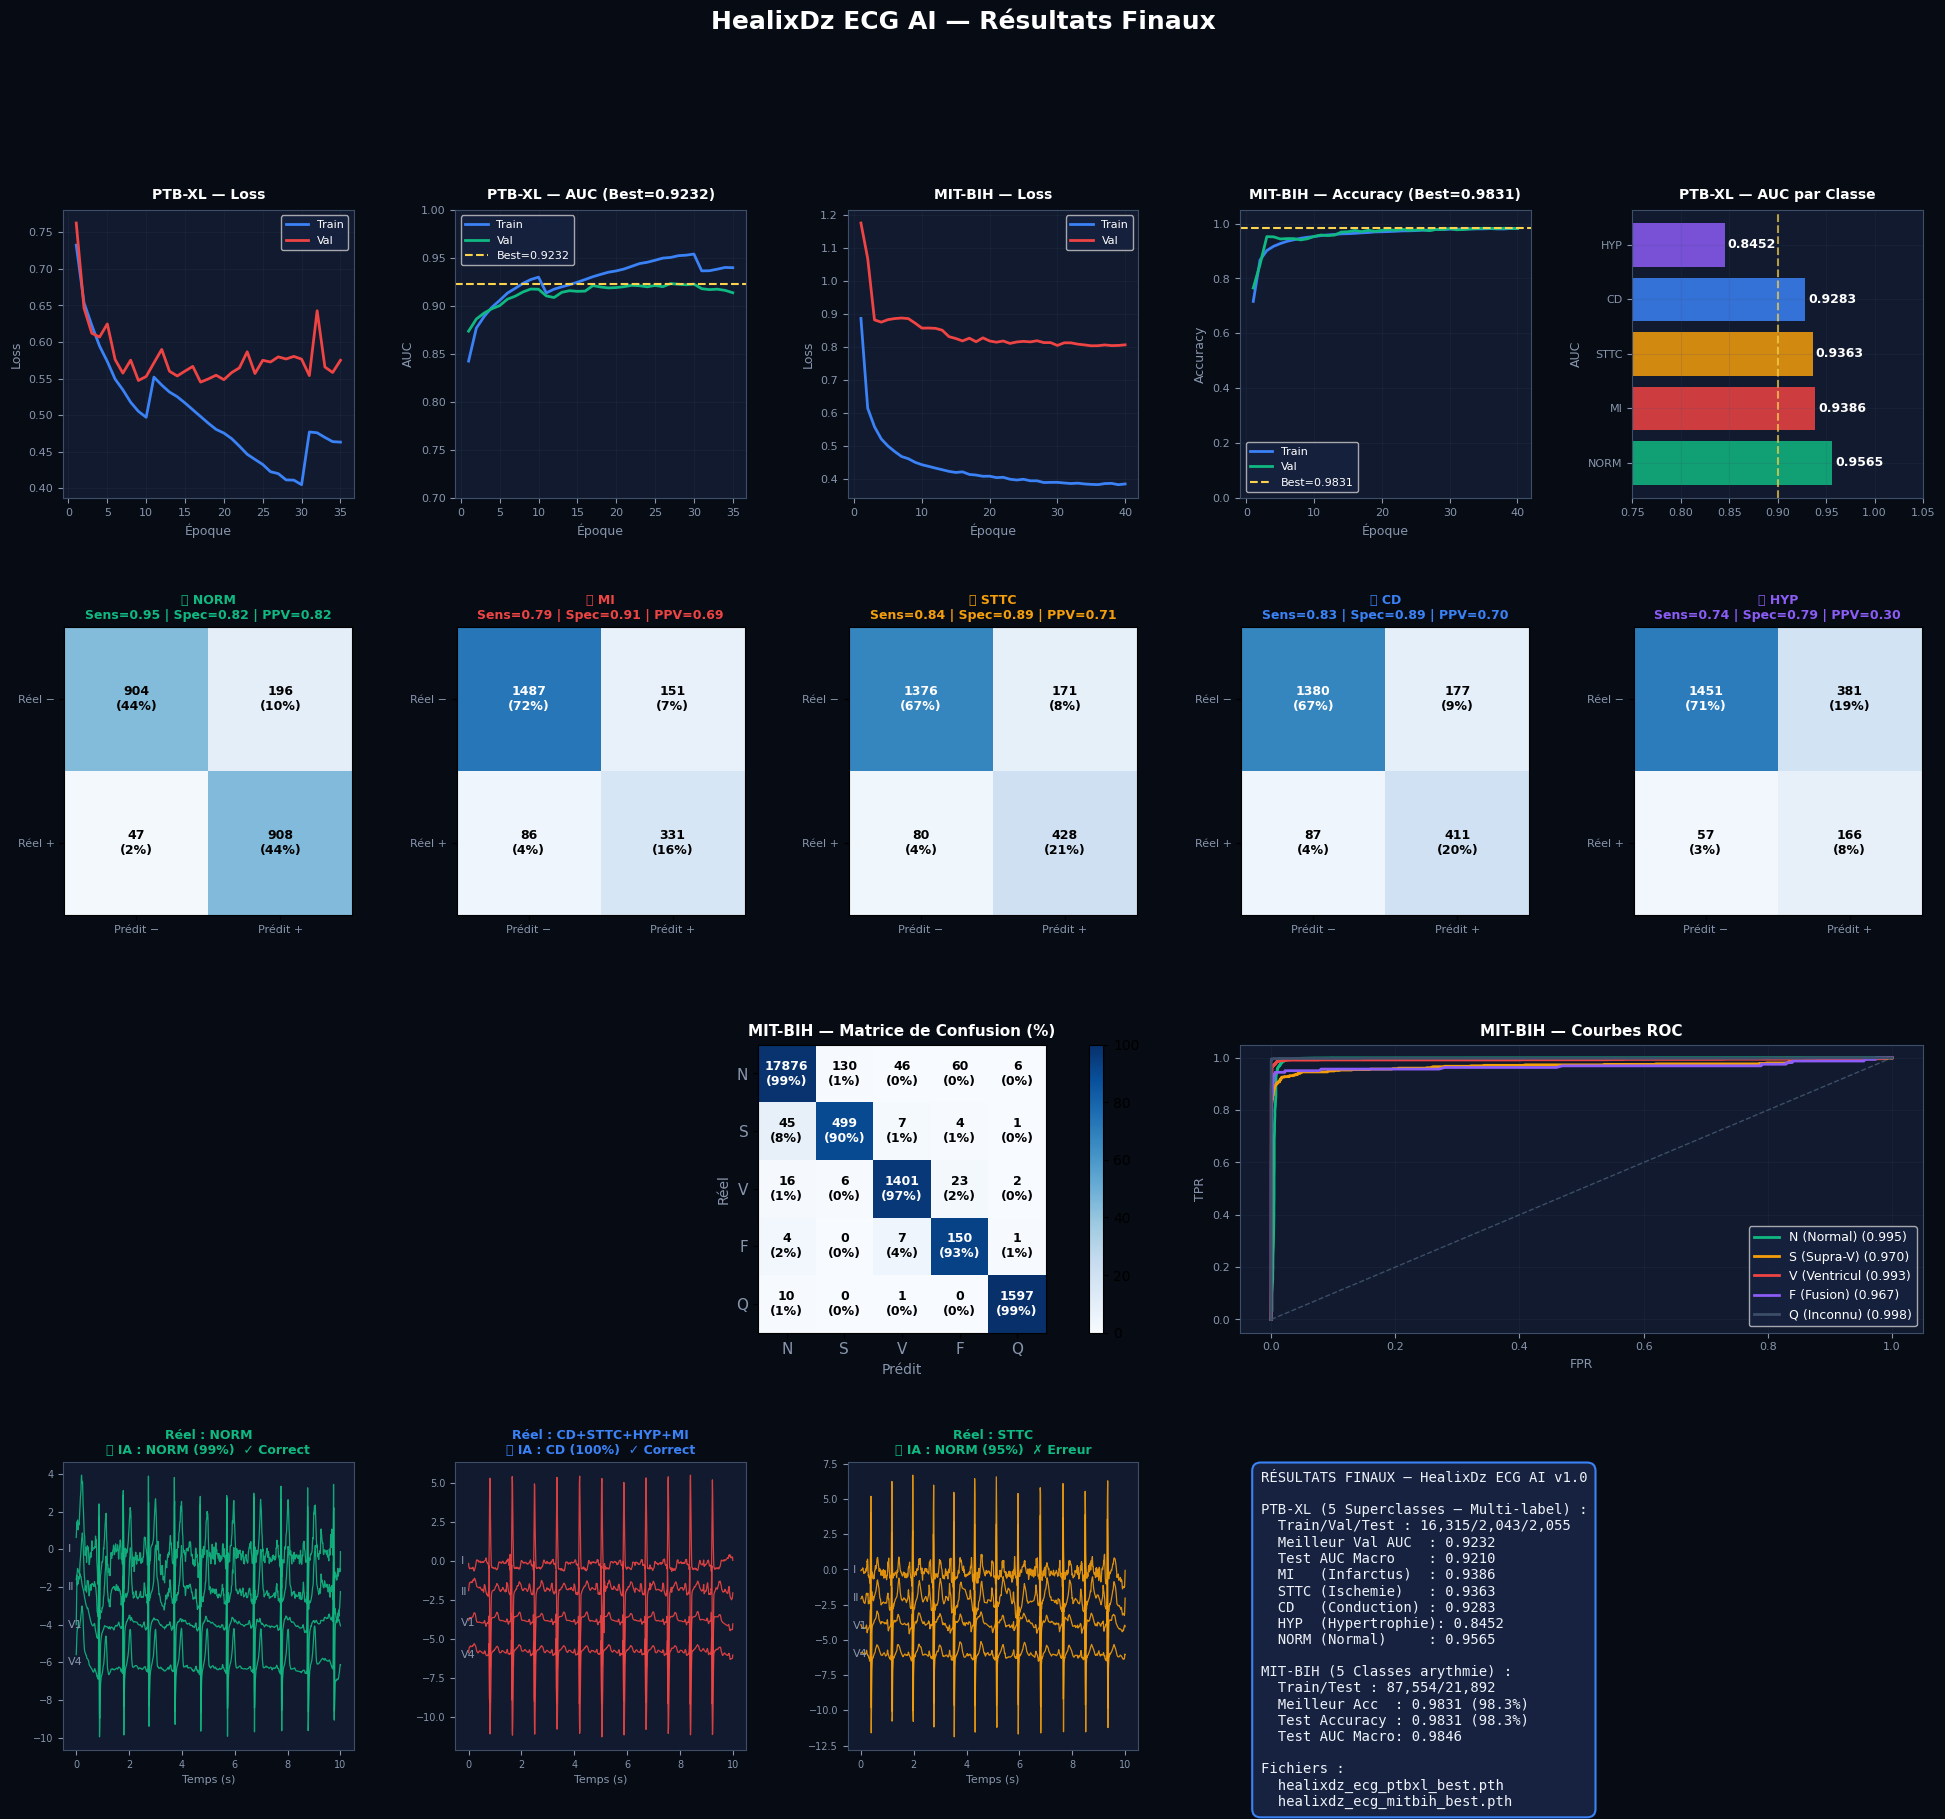

✅ Figure finale sauvegardée


In [28]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 14 CORRIGÉE — VISUALISATIONS FINALES
# ══════════════════════════════════════════════════════════════════

# ── Définitions manquantes ────────────────────────────────────────
COLORS = {
    'NORM': '#10B981',
    'MI'  : '#EF4444',
    'STTC': '#F59E0B',
    'CD'  : '#3B82F6',
    'HYP' : '#8B5CF6',
}

short_names = [
    'N (Normal)', 'S (Supra-V)', 'V (Ventriculaire)',
    'F (Fusion)', 'Q (Inconnu)'
]

from sklearn.metrics import multilabel_confusion_matrix, roc_curve

# ── Figure principale ─────────────────────────────────────────────
fig = plt.figure(figsize=(24, 20), facecolor='#060B14')
fig.suptitle('HealixDz ECG AI — Résultats Finaux',
             fontsize=18, fontweight='bold', color='white', y=0.98)

gs = gridspec.GridSpec(4, 5, figure=fig, hspace=0.45, wspace=0.35)

def style_ax(ax, title='', xlabel='', ylabel=''):
    ax.set_facecolor('#111A2E')
    ax.set_title(title, color='white', fontsize=10, fontweight='bold', pad=8)
    ax.set_xlabel(xlabel, color='#8896AD', fontsize=9)
    ax.set_ylabel(ylabel, color='#8896AD', fontsize=9)
    ax.tick_params(colors='#8896AD', labelsize=8)
    for sp in ax.spines.values():
        sp.set_edgecolor('#3D4E68')
    ax.grid(True, alpha=0.15, color='#3D4E68')

# ── ROW 1 — Courbes entraînement ─────────────────────────────────
ep  = range(1, len(history_ptbxl['train_loss']) + 1)
ep2 = range(1, len(history_mitbih['train_loss']) + 1)

ax = fig.add_subplot(gs[0, 0])
style_ax(ax, 'PTB-XL — Loss', 'Époque', 'Loss')
ax.plot(ep, history_ptbxl['train_loss'], '#3B82F6', lw=2, label='Train')
ax.plot(ep, history_ptbxl['val_loss'],   '#EF4444', lw=2, label='Val')
ax.legend(fontsize=8, facecolor='#172240', labelcolor='white')

ax = fig.add_subplot(gs[0, 1])
style_ax(ax, f'PTB-XL — AUC (Best={best_val_auc:.4f})', 'Époque', 'AUC')
ax.plot(ep, history_ptbxl['train_auc'], '#3B82F6', lw=2, label='Train')
ax.plot(ep, history_ptbxl['val_auc'],   '#10B981', lw=2, label='Val')
ax.axhline(best_val_auc, color='#FCD34D', lw=1.5, ls='--',
           label=f'Best={best_val_auc:.4f}')
ax.set_ylim(0.7, 1.0)
ax.legend(fontsize=8, facecolor='#172240', labelcolor='white')

ax = fig.add_subplot(gs[0, 2])
style_ax(ax, 'MIT-BIH — Loss', 'Époque', 'Loss')
ax.plot(ep2, history_mitbih['train_loss'], '#3B82F6', lw=2, label='Train')
ax.plot(ep2, history_mitbih['val_loss'],   '#EF4444', lw=2, label='Val')
ax.legend(fontsize=8, facecolor='#172240', labelcolor='white')

ax = fig.add_subplot(gs[0, 3])
style_ax(ax, f'MIT-BIH — Accuracy (Best={best_val_acc_mitbih:.4f})',
         'Époque', 'Accuracy')
ax.plot(ep2, history_mitbih['train_acc'], '#3B82F6', lw=2, label='Train')
ax.plot(ep2, history_mitbih['val_acc'],   '#10B981', lw=2, label='Val')
ax.axhline(best_val_acc_mitbih, color='#FCD34D', lw=1.5, ls='--',
           label=f'Best={best_val_acc_mitbih:.4f}')
ax.set_ylim(0.0, 1.05)
ax.legend(fontsize=8, facecolor='#172240', labelcolor='white')

# ── AUC par classe PTB-XL ─────────────────────────────────────────
ax = fig.add_subplot(gs[0, 4])
style_ax(ax, 'PTB-XL — AUC par Classe', '', 'AUC')
ptbxl_colors = [COLORS[c] for c in CFG['superclasses']]
bars = ax.barh(CFG['superclasses'], test_aucs,
               color=ptbxl_colors, alpha=0.85)
ax.set_xlim(0.75, 1.05)
ax.axvline(0.90, color='#FCD34D', lw=1.5, ls='--', alpha=0.7)
for bar, val in zip(bars, test_aucs):
    ax.text(val + 0.003, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', color='white',
            fontsize=9, fontweight='bold')

# ── ROW 2 — Confusion multi-label PTB-XL ─────────────────────────
for col_idx, (cls, color) in enumerate(
        zip(CFG['superclasses'], ptbxl_colors)):
    ax = fig.add_subplot(gs[1, col_idx])
    ax.set_facecolor('#111A2E')
    i = CFG['superclasses'].index(cls)
    tn, fp, fn, tp = multilabel_confusion_matrix(
        test_labels_ptbxl, test_preds_bin
    )[i].ravel()
    sens = tp / (tp + fn + 1e-8)
    spec = tn / (tn + fp + 1e-8)
    ppv  = tp / (tp + fp + 1e-8)
    cm_d = np.array([[tn, fp], [fn, tp]])
    ax.imshow(cm_d / (cm_d.sum() + 1e-8) * 100,
              cmap='Blues', vmin=0, vmax=100)
    for ci in range(2):
        for cj in range(2):
            pct = cm_d[ci, cj] / (cm_d.sum() + 1e-8) * 100
            ax.text(cj, ci,
                    f'{int(cm_d[ci,cj])}\n({pct:.0f}%)',
                    ha='center', va='center',
                    fontsize=9, fontweight='bold',
                    color='white' if pct > 50 else 'black')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['Prédit −', 'Prédit +'],
                        color='#8896AD', fontsize=8)
    ax.set_yticklabels(['Réel −', 'Réel +'],
                        color='#8896AD', fontsize=8)
    e, u, _ = URGENCE_MAP[cls]
    ax.set_title(
        f'{e} {cls}\nSens={sens:.2f} | Spec={spec:.2f} | PPV={ppv:.2f}',
        color=color, fontsize=9, fontweight='bold'
    )

# ── ROW 3 — Confusion MIT-BIH 5×5 ────────────────────────────────
ax_cm = fig.add_subplot(gs[2, :3])
ax_cm.set_facecolor('#111A2E')
cm_mitbih = confusion_matrix(final_labels, final_preds)
cm_pct    = (cm_mitbih.astype(float)
             / cm_mitbih.sum(axis=1, keepdims=True) * 100)
im = ax_cm.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
plt.colorbar(im, ax=ax_cm, fraction=0.046, pad=0.04)
cls_abbr = ['N', 'S', 'V', 'F', 'Q']
ax_cm.set_xticks(range(5)); ax_cm.set_yticks(range(5))
ax_cm.set_xticklabels(cls_abbr, color='#8896AD', fontsize=11)
ax_cm.set_yticklabels(cls_abbr, color='#8896AD', fontsize=11)
ax_cm.set_xlabel('Prédit', color='#8896AD', fontsize=10)
ax_cm.set_ylabel('Réel',   color='#8896AD', fontsize=10)
ax_cm.set_title('MIT-BIH — Matrice de Confusion (%)',
                color='white', fontsize=11, fontweight='bold')
for ci in range(5):
    for cj in range(5):
        ax_cm.text(cj, ci,
                   f'{cm_mitbih[ci,cj]}\n({cm_pct[ci,cj]:.0f}%)',
                   ha='center', va='center',
                   fontsize=9, fontweight='bold',
                   color='white' if cm_pct[ci,cj] > 50 else 'black')

# ── Courbes ROC MIT-BIH ───────────────────────────────────────────
ax_roc = fig.add_subplot(gs[2, 3:])
ax_roc.set_facecolor('#111A2E')
roc_colors = ['#10B981', '#F59E0B', '#EF4444', '#8B5CF6', '#3D4E68']
for i, (name, rc) in enumerate(zip(short_names, roc_colors)):
    if labels_bin[:, i].sum() > 0:
        fpr, tpr, _ = roc_curve(labels_bin[:, i], final_probs[:, i])
        auc_val = float(aucs_per_class[i]) \
                  if i < len(aucs_per_class) else 0.0
        ax_roc.plot(fpr, tpr, color=rc, lw=2,
                    label=f'{name[:12]} ({auc_val:.3f})')
ax_roc.plot([0, 1], [0, 1], '#3D4E68', lw=1, ls='--')
ax_roc.set_title('MIT-BIH — Courbes ROC',
                 color='white', fontsize=11, fontweight='bold')
ax_roc.set_xlabel('FPR', color='#8896AD', fontsize=9)
ax_roc.set_ylabel('TPR', color='#8896AD', fontsize=9)
ax_roc.legend(fontsize=9, facecolor='#172240', labelcolor='white')
ax_roc.tick_params(colors='#8896AD', labelsize=8)
for sp in ax_roc.spines.values():
    sp.set_edgecolor('#3D4E68')
ax_roc.grid(True, alpha=0.15, color='#3D4E68')

# ── ROW 4 — Signaux ECG + prédictions IA ─────────────────────────
model_ptbxl.eval()
target_classes = ['NORM', 'MI', 'STTC']

for col_idx, target_cls in enumerate(target_classes):
    ax = fig.add_subplot(gs[3, col_idx])
    ax.set_facecolor('#111A2E')

    # Chercher un ECG de cette classe dans le test set
    cls_ids = [
        eid for eid in test_df.index
        if target_cls in test_df.loc[eid, 'superclasses']
        and load_ptbxl_signal(eid) is not None
    ]
    if not cls_ids:
        ax.text(0.5, 0.5, 'Pas de sample\ndisponible',
                ha='center', va='center', color='#8896AD',
                transform=ax.transAxes, fontsize=10)
        continue

    ecg_id  = cls_ids[0]
    signal  = load_ptbxl_signal(ecg_id)
    proc    = preprocess_ptbxl_signal(signal)
    true_sc = test_df.loc[ecg_id, 'superclasses']

    # Inférence
    with torch.no_grad():
        logits = model_ptbxl(
            torch.tensor(proc).unsqueeze(0).to(device)
        )
        probs = torch.sigmoid(logits)[0].cpu().numpy()

    # Afficher 4 dérivations : I, II, V1, V4
    t = np.linspace(0, 10, proc.shape[1])
    for i, (li, ln) in enumerate([(0,'I'),(1,'II'),(6,'V1'),(9,'V4')]):
        offset = -i * 2.0
        ax.plot(t, proc[li] + offset,
                color=COLORS.get(target_cls, '#60A5FA'),
                lw=0.9, alpha=0.9)
        ax.text(-0.3, offset, ln,
                color='#8896AD', fontsize=8, va='center')

    pred_idx  = probs.argmax()
    pred_cls  = CFG['superclasses'][pred_idx]
    pred_conf = probs[pred_idx]
    correct   = pred_cls in true_sc
    e, u, _   = URGENCE_MAP[pred_cls]
    verdict   = '✓ Correct' if correct else '✗ Erreur'
    ax.set_title(
        f'Réel : {"+".join(true_sc)}\n'
        f'{e} IA : {pred_cls} ({pred_conf:.0%})  {verdict}',
        color=COLORS.get(pred_cls, '#60A5FA'),
        fontsize=9, fontweight='bold'
    )
    ax.set_xlabel('Temps (s)', color='#8896AD', fontsize=8)
    ax.tick_params(colors='#8896AD', labelsize=7)
    for sp in ax.spines.values():
        sp.set_edgecolor('#3D4E68')

# ── Résumé final ──────────────────────────────────────────────────
ax_sum = fig.add_subplot(gs[3, 3:])
ax_sum.set_facecolor('#111A2E')
ax_sum.axis('off')

try:
    auc_m_str = f"{auc_mitbih:.4f}"
except Exception:
    auc_m_str = "N/A"

summary = (
    "RÉSULTATS FINAUX — HealixDz ECG AI v1.0\n\n"
    f"PTB-XL (5 Superclasses — Multi-label) :\n"
    f"  Train/Val/Test : {len(train_df):,}/{len(val_df):,}/{len(test_df):,}\n"
    f"  Meilleur Val AUC  : {best_val_auc:.4f}\n"
    f"  Test AUC Macro    : {test_auc_macro:.4f}\n"
    f"  MI   (Infarctus)  : {test_aucs[1]:.4f}\n"
    f"  STTC (Ischemie)   : {test_aucs[2]:.4f}\n"
    f"  CD   (Conduction) : {test_aucs[3]:.4f}\n"
    f"  HYP  (Hypertrophie): {test_aucs[4]:.4f}\n"
    f"  NORM (Normal)     : {test_aucs[0]:.4f}\n\n"
    f"MIT-BIH (5 Classes arythmie) :\n"
    f"  Train/Test : {len(mitbih_train_ds):,}/{len(mitbih_test_ds):,}\n"
    f"  Meilleur Acc  : {best_val_acc_mitbih:.4f} "
    f"({best_val_acc_mitbih:.1%})\n"
    f"  Test Accuracy : {test_acc_mitbih:.4f} "
    f"({test_acc_mitbih:.1%})\n"
    f"  Test AUC Macro: {auc_m_str}\n\n"
    f"Fichiers :\n"
    f"  healixdz_ecg_ptbxl_best.pth\n"
    f"  healixdz_ecg_mitbih_best.pth"
)
ax_sum.text(0.03, 0.97, summary,
            transform=ax_sum.transAxes,
            color='#EDF2F9', fontsize=10, va='top',
            fontfamily='monospace',
            bbox=dict(boxstyle='round,pad=0.6',
                      facecolor='#172240',
                      edgecolor='#3B82F6',
                      linewidth=1.5))

plt.savefig(f"{CFG['output_path']}/02_final_results_ecg.png",
            dpi=150, bbox_inches='tight', facecolor='#060B14')
plt.show()
print("✅ Figure finale sauvegardée")

In [29]:
# ══════════════════════════════════════════════════════════════════
# CELLULE 15 — SAUVEGARDE RAPPORT JSON + VÉRIFICATION FICHIERS
# ══════════════════════════════════════════════════════════════════

try:
    report_cls = classification_report(
        final_labels, final_preds,
        target_names=short_names, output_dict=True, zero_division=0
    )
    mitbih_per_class = {
        n: {k: float(report_cls[n][k]) for k in ['precision','recall','f1-score']}
        for n in short_names if n in report_cls
    }
except Exception:
    mitbih_per_class = {}

try:
    aucs_per_class_list = [float(a) for a in aucs_per_class]
except Exception:
    aucs_per_class_list = []

final_metrics = {
    'model_info': {
        'architecture'  : 'ResNet1D-34 (HealixDz ECG Net)',
        'framework'     : f'PyTorch {torch.__version__}',
        'n_params_ptbxl': f'{params_ptbxl:.1f}M',
        'n_params_mitbih': f'{params_mitbih:.1f}M',
    },
    'datasets': {
        'ptbxl': {
            'url'     : 'https://www.kaggle.com/datasets/khyeh0719/ptb-xl-dataset',
            'records' : len(df_meta),
            'classes' : 5,
            'multilabel': True,
            'splits'  : {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
        },
        'mitbih': {
            'url'     : 'https://www.kaggle.com/datasets/shayanfazeli/heartbeat',
            'train'   : len(mitbih_train_ds),
            'test'    : len(mitbih_test_ds),
            'classes' : 5,
        },
    },
    'ptbxl_results': {
        'best_val_auc'  : float(best_val_auc),
        'test_auc_macro': float(test_auc_macro),
        'per_class_auc' : dict(zip(CFG['superclasses'], [float(a) for a in test_aucs])),
    },
    'mitbih_results': {
        'best_val_acc'  : float(best_val_acc_mitbih),
        'test_accuracy' : float(test_acc_mitbih),
        'auc_macro'     : float(auc_mitbih) if 'auc_mitbih' in dir() else 0,
        'per_class_auc' : dict(zip(short_names, aucs_per_class_list)),
        'per_class_f1'  : mitbih_per_class,
    },
    'config': {
        'batch_size' : CFG['batch_size'],
        'epochs'     : CFG['epochs'],
        'lr'         : CFG['lr'],
        'dropout'    : CFG['dropout'],
        'patience'   : CFG['patience'],
    }
}

metrics_path = f"{CFG['output_path']}/healixdz_ecg_metrics.json"
with open(metrics_path, 'w', encoding='utf-8') as f:
    json.dump(final_metrics, f, indent=2, ensure_ascii=False)

# ── Vérification fichiers sauvegardés ────────────────────────────
print(f"\n{'═'*65}")
print(f"  FICHIERS SAUVEGARDÉS — HealixDz ECG AI")
print(f"{'═'*65}")

output_dir = Path(CFG['output_path'])
saved_files = list(output_dir.glob('*.pth')) + \
              list(output_dir.glob('*.json')) + \
              list(output_dir.glob('*.png'))

for f in sorted(saved_files):
    size_mb = f.stat().st_size / 1e6
    print(f"  ✅ {f.name:<50} {size_mb:>7.1f} MB")

print(f"\n{'═'*65}")
print(f"  RÉSUMÉ FINAL — HealixDz ECG AI v1.0")
print(f"{'═'*65}")
print(f"\n  📊 PTB-XL (5 Superclasses multi-label) :")
print(f"     Val AUC Macro  : {best_val_auc:.4f}")
print(f"     Test AUC Macro : {test_auc_macro:.4f}")
print(f"     Par classe :")
for cls, auc_val in zip(CFG['superclasses'], test_aucs):
    e, u, _ = URGENCE_MAP[cls]
    print(f"       {e} {cls:5s} : AUC={auc_val:.4f}  ({u})")

print(f"\n  📊 MIT-BIH (5 Classes arythmie) :")
print(f"     Test Accuracy  : {test_acc_mitbih:.4f} ({test_acc_mitbih:.1%})")
try:
    print(f"     Test AUC Macro : {auc_mitbih:.4f}")
except Exception:
    pass

print(f"\n  ✅ ENTRAÎNEMENT TERMINÉ — HealixDz ECG AI v1.0")
print(f"{'═'*65}")


═════════════════════════════════════════════════════════════════
  FICHIERS SAUVEGARDÉS — HealixDz ECG AI
═════════════════════════════════════════════════════════════════
  ✅ 02_final_results_ecg.png                               0.7 MB
  ✅ healixdz_ecg_metrics.json                              0.0 MB
  ✅ healixdz_ecg_mitbih_best.pth                           4.6 MB
  ✅ healixdz_ecg_ptbxl_best.pth                           88.6 MB

═════════════════════════════════════════════════════════════════
  RÉSUMÉ FINAL — HealixDz ECG AI v1.0
═════════════════════════════════════════════════════════════════

  📊 PTB-XL (5 Superclasses multi-label) :
     Val AUC Macro  : 0.9232
     Test AUC Macro : 0.9210
     Par classe :
       🟢 NORM  : AUC=0.9565  (Normal)
       🔴 MI    : AUC=0.9386  (URGENCE ABSOLUE)
       🟠 STTC  : AUC=0.9363  (URGENT)
       🟡 CD    : AUC=0.9283  (SURVEILLANCE)
       🟡 HYP   : AUC=0.8452  (SUIVI)

  📊 MIT-BIH (5 Classes arythmie) :
     Test Accuracy  : 0.9831 (98